# Detecção de outliers em dados climáticos

**Projeto Integrador — histórico climático e El Niño**

Neste notebook comparamos três métodos para encontrar valores fora do comum
(outliers) em dados de temperatura, umidade e chuva:

1. **ARIMA + Z-score**: prevê o próximo valor e marca quando o erro da previsão é muito grande.
2. **Isolation Forest**: olha as três variáveis juntas e marca combinações raras.
3. **Filtro de Hampel**: compara cada valor com a mediana dos dias vizinhos.

Um outlier **não é necessariamente um erro**. Ele pode ser um evento real,
como uma frente fria ou uma chuva muito forte.

In [1]:
import warnings
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from statsmodels.tsa.statespace.sarimax import SARIMAX

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
CORES = {"ARIMA": "tab:blue", "IForest": "tab:red", "Hampel": "tab:green"}
SEED = 42
warnings.filterwarnings("ignore")   # avisos de convergência do statsmodels

## 1. Dados

São dados de **reanálise ERA5-Land** extraídos do banco do projeto, com uma
observação a cada 12 horas (00h e 12h UTC) de 2015 a 2025. Foi escolhido um
município por estado:

| Município | Clima |
|---|---|
| Manaus/AM | equatorial úmido |
| Feira de Santana/BA | semiárido |
| Goiânia/GO | tropical com estação seca |
| Porto Alegre/RS | subtropical |

Salvador ficou de fora porque não tem dados: o ponto da grade mais próximo
cai no mar.

No Colab, o arquivo `clima_4_municipios.csv` é lido direto do Google Drive.
Coloque o CSV no seu Drive e ajuste `CAMINHO_DRIVE` se ele estiver em
outra pasta. Ao rodar, o Colab pede permissão para acessar o Drive.

In [2]:
from pathlib import Path

CAMINHO_DRIVE = "/content/drive/MyDrive/clima_4_municipios.csv"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    ARQUIVO = CAMINHO_DRIVE
except ImportError:  # fora do Colab: usa o arquivo local
    ARQUIVO = "clima_4_municipios.csv"

if not Path(ARQUIVO).exists():
    raise FileNotFoundError(f"CSV não encontrado em {ARQUIVO}; ajuste CAMINHO_DRIVE")

df = pd.read_csv(ARQUIVO, parse_dates=["datetime"])
VARIAVEIS = ["temperatura", "umidade", "precipitacao"]
UNIDADE = {"temperatura": "°C", "umidade": "%", "precipitacao": "mm/12h"}
print(df.shape)
df.head()

(32144, 7)


,datetime,codigo_ibge,municipio,uf,temperatura,umidade,precipitacao
0,2015-01-01 00:00:00+00:00,1302603,Manaus,AM,26.155176,85.881409,NaN
1,2015-01-01 00:00:00+00:00,2910800,Feira de Santana,BA,24.784082,75.354805,NaN
2,2015-01-01 00:00:00+00:00,5208707,Goiânia,GO,23.258691,85.378658,NaN
3,2015-01-01 00:00:00+00:00,4314902,Porto Alegre,RS,25.694238,84.287833,NaN
4,2015-01-01 12:00:00+00:00,1302603,Manaus,AM,26.324609,86.075854,0.461289


In [3]:
print("Valores faltando por município:")
display(df.groupby("municipio")[VARIAVEIS].apply(lambda d: d.isna().sum()))
df.groupby("municipio")[VARIAVEIS].describe().T.round(1)

Valores faltando por município:


,temperatura,umidade,precipitacao
municipio,,,
Feira de Santana,0,0,132
Goiânia,0,0,132
Manaus,0,0,132
Porto Alegre,0,0,132


municipio           Feira de Santana  Goiânia  Manaus  Porto Alegre
temperatura  count            8036.0   8036.0  8036.0        8036.0
             mean               24.5     23.5    26.1          19.2
             std                 2.5      2.5     1.6           5.0
             min                18.3     11.3    21.6           3.0
             25%                22.7     21.8    25.0          15.8
             50%                24.5     23.2    25.9          19.7
             75%                26.4     24.9    26.9          23.0
             max                33.7     33.7    33.7          32.6
umidade      count            8036.0   8036.0  8036.0        8036.0
             mean               76.7     65.0    86.2          80.3
             std                11.9     19.4     8.9          10.2
             min                43.9     14.7    36.2          41.1
             25%                68.1     50.2    82.9          73.2
             50%                78.1     66.6    88.1          81.2
             75%                86.6     81.8    91.6          88.5
             max                99.0     99.5   100.0          99.2
precipitacao count            7904.0   7904.0  7904.0        7904.0
             mean                1.0      1.6     3.7           2.0
             std                 2.4      3.7     6.3           5.4
             min                 0.0      0.0     0.0           0.0
             25%                 0.1      0.0     0.1           0.0
             50%                 0.4      0.0     1.3           0.0
             75%                 1.0      1.4     5.2           0.9
             max                72.8     70.0   118.9          88.6

A chuva falta sempre no dia 1º de cada mês às 00h. Isso é uma falha do
carregamento dos dados, não um dia sem chuva, por isso esses valores ficam
como vazios e não são trocados por zero.

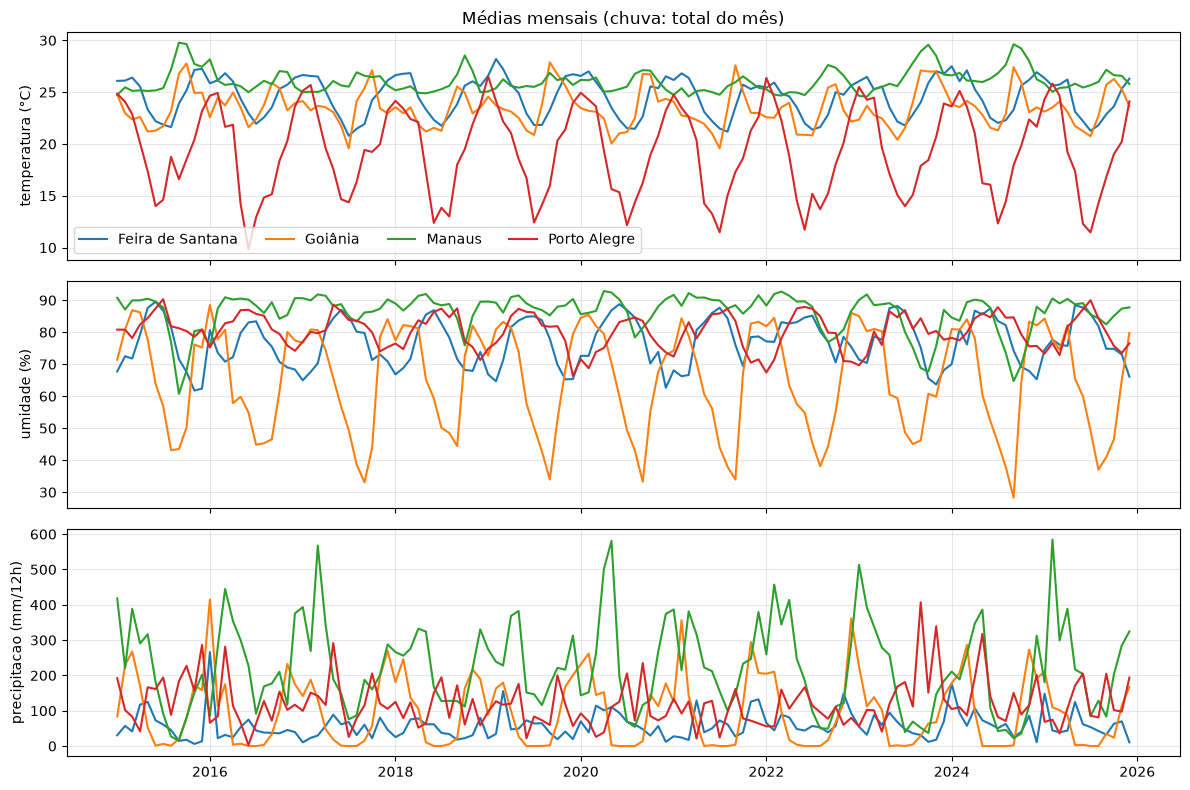

In [4]:
fig, eixos = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for var, ax in zip(VARIAVEIS, eixos):
    for mun, g in df.groupby("municipio"):
        mensal = g.set_index("datetime")[var].resample("MS")
        mensal = mensal.sum() if var == "precipitacao" else mensal.mean()
        ax.plot(mensal, label=mun)
    ax.set_ylabel(f"{var} ({UNIDADE[var]})")
eixos[0].legend(ncol=4)
eixos[0].set_title("Médias mensais (chuva: total do mês)")
plt.tight_layout(); plt.show()

## 2. Preparação

As séries têm dois ciclos fortes: o **anual** (estações do ano) e o
**diário** (00h UTC é noite e 12h UTC é manhã). Se não os removermos, os
métodos vão marcar o próprio ciclo como anomalia.

Por isso, calculamos a **anomalia**, que é o valor observado menos o valor
esperado para aquela época do ano e horário. O valor esperado é estimado
com uma regressão de senos e cossenos.

Os dados são divididos em **treino (2015–2021)** e **teste (2022–2025)**.
Tudo é ajustado só com o treino, para que o teste seja uma avaliação honesta.

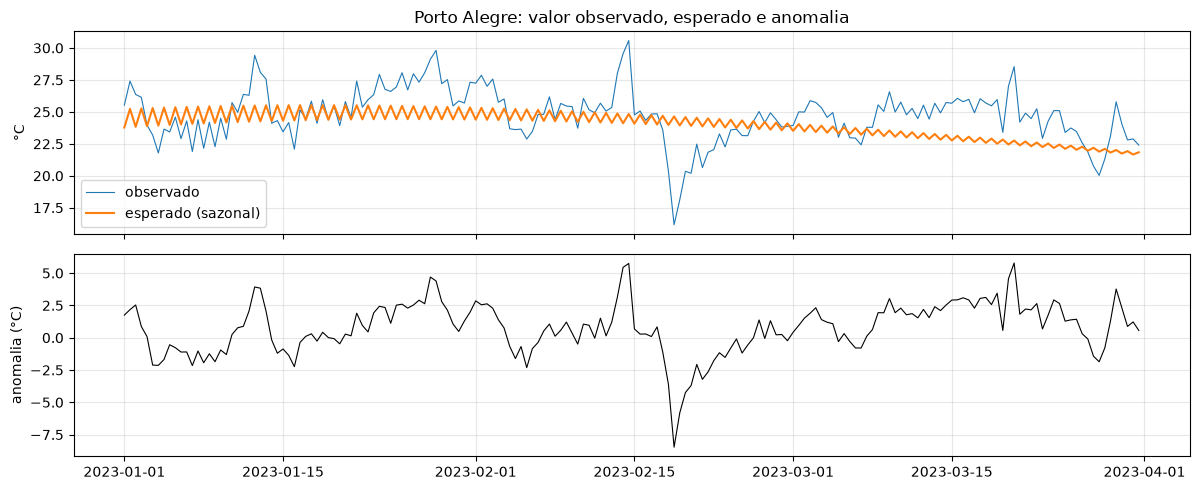

In [5]:
FIM_TREINO = "2021-12-31 23:59"

def preparar(df, municipio):
    s = df[df.municipio == municipio].set_index("datetime")[VARIAVEIS].asfreq("12h")
    s.attrs["municipio"] = municipio
    return s

def sazonalidade(y, treino):
    # Ciclo anual (3 harmônicos) com efeito diferente para 00h e 12h
    ang = 2 * np.pi * (y.index.day_of_year.to_numpy() - 1) / 365.25
    h12 = (y.index.hour == 12).astype(float)
    cols = [np.ones(len(y)), h12]
    for k in (1, 2, 3):
        for f in (np.sin(k * ang), np.cos(k * ang)):
            cols += [f, f * h12]
    X = np.column_stack(cols)
    ok = treino & y.notna().to_numpy()
    beta = np.linalg.lstsq(X[ok], y.to_numpy()[ok], rcond=None)[0]
    esperado = pd.Series(X @ beta, index=y.index)
    return esperado, y - esperado

MUNICIPIOS = sorted(df.municipio.unique())
series = {m: preparar(df, m) for m in MUNICIPIOS}
treino = {m: (s.index <= pd.Timestamp(FIM_TREINO, tz="UTC")) for m, s in series.items()}

s, tr = series["Porto Alegre"], treino["Porto Alegre"]
esp, anom = sazonalidade(s.temperatura, tr)
jan = slice("2023-01-01", "2023-03-31")
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(s.temperatura[jan], lw=0.8, label="observado")
ax[0].plot(esp[jan], lw=1.5, label="esperado (sazonal)")
ax[0].set_ylabel("°C"); ax[0].legend()
ax[1].plot(anom[jan], lw=0.8, color="k"); ax[1].set_ylabel("anomalia (°C)")
ax[0].set_title("Porto Alegre: valor observado, esperado e anomalia")
plt.tight_layout(); plt.show()

## 3. Método 1 — ARIMA + Z-score

1. Ajustamos um modelo ARIMA sobre a anomalia do período de treino, escolhendo a ordem (p, q) entre 0 e 2 pelo menor BIC.
2. Com os parâmetros fixos, o modelo prevê cada valor usando só os valores anteriores.
3. Calculamos o erro da previsão (resíduo) e o transformamos em Z-score com a média e o desvio do treino.
4. O valor é marcado como outlier se **|Z| > 3**.
5. **Eco:** quando aparece um pico, o modelo usa esse valor errado para
   prever o instante seguinte e erra de novo, com o sinal contrário. Esse
   segundo alarme é só um "eco" do primeiro, então descartamos ele.

O método é aplicado na temperatura, na umidade e na chuva. Para a chuva
usamos log(1 + chuva), que diminui o peso das chuvas muito grandes, e só
marcamos **Z > 3** (choveu muito mais que o previsto). Chover menos que o
previsto não é tratado como anomalia.

In [6]:
def arima_z(y, treino, limiar=3.0):
    _, anom = sazonalidade(y, treino)
    melhor = None
    for p in range(3):
        for q in range(3):
            if p == q == 0:
                continue
            res = SARIMAX(anom[treino], order=(p, 0, q)).fit(disp=False)
            if melhor is None or res.bic < melhor.bic:
                melhor = res
    previsao = melhor.apply(anom, refit=False)   # mesmos parâmetros, série toda
    residuo = anom - previsao.fittedvalues
    residuo.iloc[:10] = np.nan                   # início instável do filtro
    z = (residuo - residuo[treino].mean()) / residuo[treino].std()
    flag = z.abs() > limiar
    eco = flag & flag.shift(1, fill_value=False) & (np.sign(z) != np.sign(z.shift(1)))
    return z, flag & ~eco, melhor.model.order

flags = {m: pd.DataFrame(index=s.index) for m, s in series.items()}
ordens = []
for m, s in series.items():
    for var in ["temperatura", "umidade"]:
        z, flag, ordem = arima_z(s[var], treino[m])
        flags[m][f"ARIMA_{var}"] = flag
        ordens.append({"município": m, "variável": var, "ordem ARIMA": ordem,
                       "% outliers": round(100 * flag.mean(), 2)})
    # chuva: usa log(1 + chuva) e marca só o excesso (Z positivo)
    z, _, ordem = arima_z(np.log1p(s.precipitacao), treino[m])
    flags[m]["ARIMA_precipitacao"] = z > 3
    ordens.append({"município": m, "variável": "precipitacao", "ordem ARIMA": ordem,
                   "% outliers": round(100 * (z > 3).mean(), 2)})
pd.DataFrame(ordens)

,município,variável,ordem ARIMA,% outliers
0,Feira de Santana,temperatura,"(2, 0, 1)",1.39
1,Feira de Santana,umidade,"(2, 0, 2)",1.18
2,Feira de Santana,precipitacao,"(2, 0, 2)",1.95
3,Goiânia,temperatura,"(2, 0, 1)",1.14
4,Goiânia,umidade,"(2, 0, 2)",1.36
5,Goiânia,precipitacao,"(2, 0, 0)",1.18
6,Manaus,temperatura,"(2, 0, 2)",0.55
7,Manaus,umidade,"(2, 0, 2)",0.91
8,Manaus,precipitacao,"(2, 0, 0)",0.34
9,Porto Alegre,temperatura,"(1, 0, 2)",1.19


## 4. Método 2 — Isolation Forest

O Isolation Forest separa os dados com cortes aleatórios. Pontos raros são
isolados com poucos cortes e recebem uma pontuação de anomalia maior.

Usamos cinco variáveis **juntas**:

- a anomalia de temperatura e a anomalia de umidade;
- log(1 + chuva), em que o log diminui o peso das chuvas muito grandes;
- o **salto** de temperatura e de umidade: quanto o valor foge da média do
  mesmo horário no dia anterior e no dia seguinte.

Sem os saltos, o modelo só vê o valor do instante e não percebe um pico em
um dia que já estava quente.

O modelo é treinado com 2015–2021 e supomos que **2%** dos dados sejam
anomalias (`contamination=0.02`). Esse valor é uma suposição nossa, não um
dado conhecido.

In [7]:
def isolation_forest(s, treino, contaminacao=0.02):
    X = pd.DataFrame({
        "anom_temp": sazonalidade(s.temperatura, treino)[1],
        "anom_umid": sazonalidade(s.umidade, treino)[1],
        "log_chuva": np.log1p(s.precipitacao),
    })
    for v in ("temp", "umid"):   # salto: diferença para a média do dia anterior e do seguinte
        X[f"salto_{v}"] = X[f"anom_{v}"] - (X[f"anom_{v}"].shift(2) + X[f"anom_{v}"].shift(-2)) / 2
    ok = X.notna().all(axis=1)          # linhas com valor faltando não são classificadas
    modelo = IsolationForest(n_estimators=300, contamination=contaminacao, random_state=SEED)
    modelo.fit(X[ok & treino])
    flag = pd.Series(False, index=s.index)
    flag[ok] = modelo.predict(X[ok]) == -1
    return flag

for m, s in series.items():
    flags[m]["IForest"] = isolation_forest(s, treino[m])

pd.DataFrame({m: {"% treino": 100 * f.IForest[treino[m]].mean(),
                  "% teste": 100 * f.IForest[~treino[m]].mean()}
              for m, f in flags.items()}).T.round(2)

,% treino,% teste
Feira de Santana,1.97,2.36
Goiânia,1.97,2.12
Manaus,1.97,3.42
Porto Alegre,1.97,2.57


No treino a taxa é 2% por construção. No teste ela fica um pouco diferente,
porque os anos recentes não se comportam exatamente como os do treino.

## 5. Método 3 — Filtro de Hampel

Para cada valor, olhamos uma janela de **15 dias antes e 15 dias depois**,
sempre no mesmo horário (00h com 00h e 12h com 12h), e calculamos:

- **mediana** da janela;
- **MAD**: a mediana das distâncias até a mediana;
- **R** = |valor − mediana| / (1,4826 × MAD).

O valor é marcado como outlier se **R > 3**. Mediana e MAD quase não são
afetadas pelo próprio outlier, por isso o método é chamado de "robusto".

O método é aplicado na temperatura e na umidade, e nenhum valor é alterado:
só marcamos. A chuva fica de fora: como ela tem muitos zeros, a mediana e o
MAD da janela ficam perto de zero e qualquer chuva moderada seria marcada
(em Porto Alegre, quase 10% dos dados).

In [8]:
def hampel(y, meia_janela_dias=15, limiar=3.0):
    k = meia_janela_dias
    flag = pd.Series(False, index=y.index)
    for hora in (0, 12):
        x = y[y.index.hour == hora].to_numpy()
        janelas = sliding_window_view(np.pad(x, k, constant_values=np.nan), 2 * k + 1)
        mediana = np.nanmedian(janelas, axis=1)
        mad = np.nanmedian(np.abs(janelas - mediana[:, None]), axis=1)
        r = np.abs(x - mediana) / np.maximum(1.4826 * mad, 1e-6)
        poucos_dados = np.isfinite(janelas).sum(axis=1) < k      # janela com menos da metade dos dados
        flag[y.index.hour == hora] = (r > limiar) & ~poucos_dados
    return flag

for m, s in series.items():
    for var in ["temperatura", "umidade"]:
        flags[m][f"Hampel_{var}"] = hampel(s[var])

## 6. Comparação dos métodos

Para comparar, cada instante (município + data/hora) é marcado por um método
quando ele sinaliza **qualquer** variável.

In [9]:
METODOS = ["ARIMA", "IForest", "Hampel"]
tabela = []
for m, f in flags.items():
    t = pd.DataFrame({
        "municipio": m,
        "ARIMA": f.ARIMA_temperatura | f.ARIMA_umidade | f.ARIMA_precipitacao,
        "IForest": f.IForest,
        "Hampel": f.Hampel_temperatura | f.Hampel_umidade,
    })
    tabela.append(t)
F = pd.concat(tabela).rename_axis("datetime").reset_index()

contagem = F.groupby("municipio")[METODOS].sum()
contagem.loc["Total"] = contagem.sum()
display(contagem)

pct = (100 * F[METODOS].mean()).round(2)
print("Percentual de instantes marcados:", pct.to_dict())

,ARIMA,IForest,Hampel
municipio,,,
Feira de Santana,255,170,257
Goiânia,226,163,265
Manaus,114,201,148
Porto Alegre,292,176,250
Total,887,710,920


Percentual de instantes marcados: {'ARIMA': 2.76, 'IForest': 2.21, 'Hampel': 2.86}


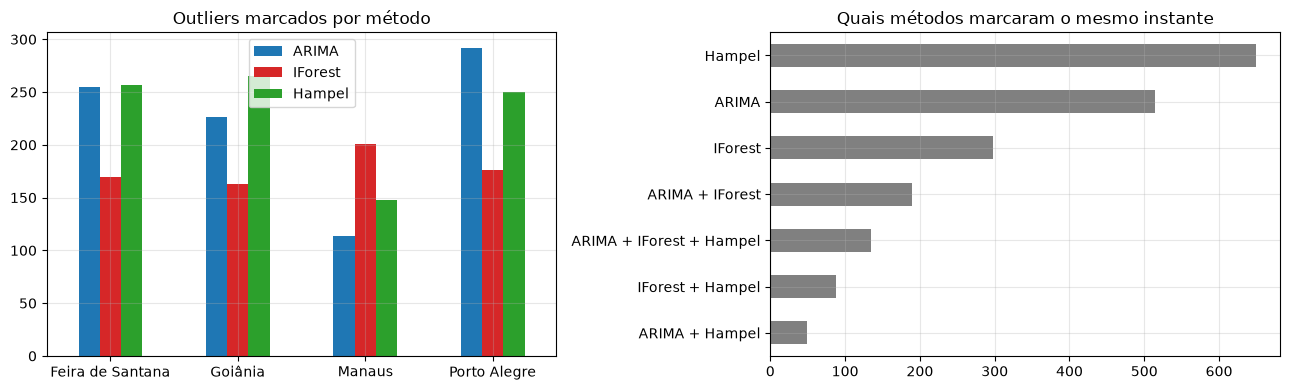

Instantes marcados por pelo menos um método: 1922
Marcados por só um método: 1461 (76%)
Marcados pelos três: 134


In [10]:
padrao = F[METODOS].apply(lambda r: " + ".join(m for m in METODOS if r[m]), axis=1)
concordancia = padrao[padrao != ""].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
F.groupby("municipio")[METODOS].sum().plot.bar(ax=ax[0], rot=0, color=[CORES[m] for m in METODOS])
ax[0].set_title("Outliers marcados por método"); ax[0].set_xlabel("")
concordancia.sort_values().plot.barh(ax=ax[1], color="gray")
ax[1].set_title("Quais métodos marcaram o mesmo instante")
plt.tight_layout(); plt.show()

total = concordancia.sum()
so_um = concordancia[[k for k in concordancia.index if "+" not in k]].sum()
print(f"Instantes marcados por pelo menos um método: {total}")
print(f"Marcados por só um método: {so_um} ({100 * so_um / total:.0f}%)")
print(f"Marcados pelos três: {concordancia.get('ARIMA + IForest + Hampel', 0)}")

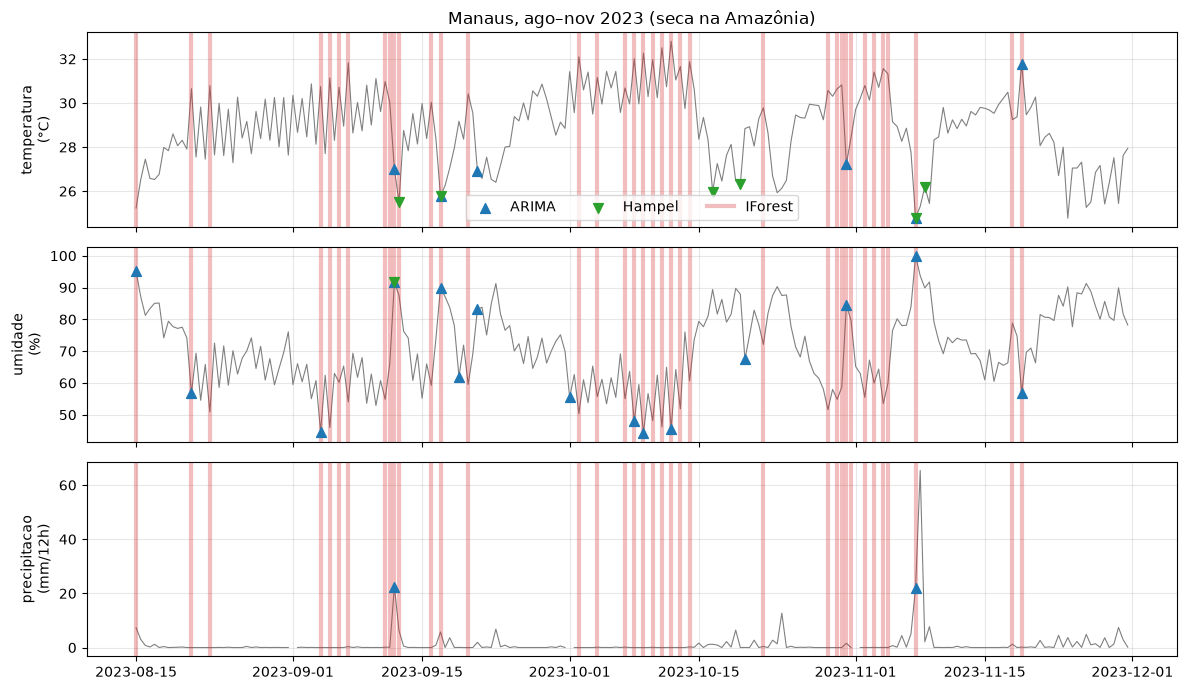

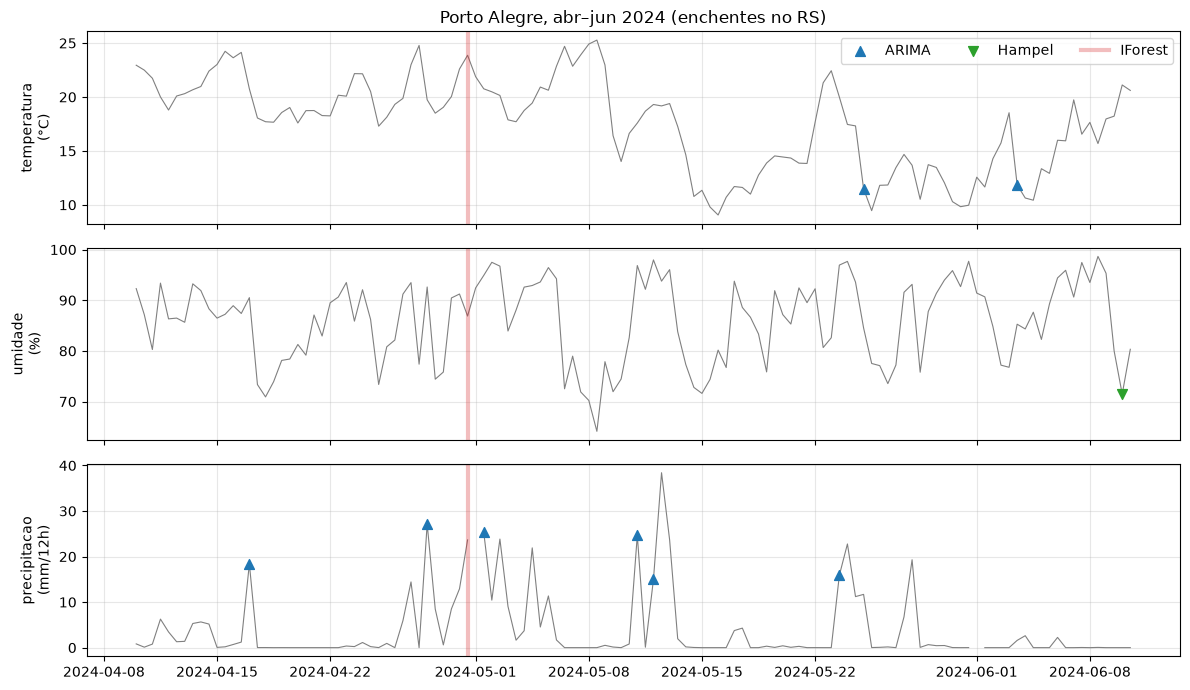

In [11]:
def grafico_periodo(m, inicio, fim, titulo):
    s = series[m].loc[inicio:fim]
    f = flags[m].loc[inicio:fim]
    fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    for a, var in zip(ax, VARIAVEIS):
        a.plot(s[var], color="gray", lw=0.8)
        a.set_ylabel(f"{var}\n({UNIDADE[var]})")
        for t in f.index[f.IForest]:
            a.axvline(t, color=CORES["IForest"], alpha=0.3, lw=3)
        for metodo, marcador in [("ARIMA", "^"), ("Hampel", "v")]:
            coluna = f"{metodo}_{var}"
            if coluna in f:          # o Hampel não é aplicado na chuva
                t = f.index[f[coluna]]
                a.scatter(t, s.loc[t, var], color=CORES[metodo], marker=marcador, s=50, zorder=3, label=metodo)
    ax[0].plot([], [], color=CORES["IForest"], lw=3, alpha=0.3, label="IForest")
    ax[0].legend(ncol=3)
    ax[0].set_title(titulo)
    plt.tight_layout(); plt.show()

grafico_periodo("Manaus", "2023-08-15", "2023-11-30", "Manaus, ago–nov 2023 (seca na Amazônia)")
grafico_periodo("Porto Alegre", "2024-04-10", "2024-06-10", "Porto Alegre, abr–jun 2024 (enchentes no RS)")

In [12]:
print("Outliers por ano em Manaus:")
F[F.municipio == "Manaus"].groupby(F.datetime.dt.year)[METODOS].sum().T

Outliers por ano em Manaus:


datetime,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
ARIMA,22,7,6,7,3,13,4,7,19,19,7
IForest,46,22,4,5,5,12,7,11,45,35,9
Hampel,8,2,16,9,17,16,9,11,21,16,23


## 7. Teste com anomalias artificiais

Como não sabemos quais outliers são "verdadeiros", criamos alguns: colocamos
**20 picos artificiais** de ±5 desvios no período de teste, primeiro na
temperatura e depois na umidade, e medimos duas coisas:

- **taxa de acerto** (*recall*): quantos dos picos o método encontrou;
- **alarmes novos**: marcações que surgiram por causa do pico, mas fora dele
  (alarmes falsos provocados pelo pico).

Os parâmetros dos métodos (limiares, contaminação, janela) foram escolhidos
fazendo esse mesmo teste no período de **treino**, procurando acertar muito
sem marcar dados demais. Assim o teste abaixo, feito em 2022–2025, não foi
usado para ajustar nada.

In [13]:
def detectar(s, var):
    return {
        "ARIMA": arima_z(s[var], treino[m])[1],
        "IForest": isolation_forest(s, treino[m]),
        "Hampel": hampel(s[var]),
    }

rng = np.random.default_rng(SEED)
resultado = []
for m, s in series.items():
    teste = ~treino[m]
    for var in ["temperatura", "umidade"]:
        antes = detectar(s, var)
        pos = rng.choice(np.flatnonzero(teste), size=20, replace=False)
        desvio = s[var][teste].diff(2).std()      # variação típica de um dia para o outro
        s2 = s.copy()
        s2.iloc[pos, s2.columns.get_loc(var)] += rng.choice([-5, 5], size=20) * desvio
        s2["umidade"] = s2.umidade.clip(0, 100)  # umidade não passa de 100%
        injetado = pd.Series(False, index=s.index); injetado.iloc[pos] = True
        for metodo, f in detectar(s2, var).items():
            resultado.append({"municipio": m, "variavel": var, "metodo": metodo,
                              "acertos": int((f & injetado).sum()),
                              "alarmes novos": int((f & ~injetado & ~antes[metodo]).sum())})

R = pd.DataFrame(resultado)
resumo = R.groupby("metodo")[["acertos", "alarmes novos"]].sum() / (20 * 2 * len(series))
resumo.columns = ["taxa de acerto", "alarmes novos por pico"]
display(resumo.round(2))
R.pivot_table(index=["municipio", "variavel"], columns="metodo", values="acertos").rename_axis(columns="picos encontrados (de 20)")

,taxa de acerto,alarmes novos por pico
metodo,,
ARIMA,0.86,0.13
Hampel,0.76,0.01
IForest,0.69,0.07


picos encontrados (de 20)     ARIMA  Hampel  IForest
municipio        variavel                           
Feira de Santana temperatura   19.0    15.0     17.0
                 umidade       15.0    11.0      7.0
Goiânia          temperatura   20.0    17.0     15.0
                 umidade       19.0    14.0     15.0
Manaus           temperatura   20.0    20.0     18.0
                 umidade       13.0    14.0     12.0
Porto Alegre     temperatura   19.0    19.0     17.0
                 umidade       12.0    12.0      9.0

## 8. Conclusão

**O que encontramos:**

- Os três métodos marcaram poucos dados: **2,76%** (ARIMA), **2,21%** (Isolation Forest) e **2,86%** (Hampel) dos instantes.
- Eles **concordam pouco**. Dos 1.922 instantes marcados por algum método, **76%** foram marcados por um só, e apenas 134 pelos três. Cada método procura um tipo diferente de "estranho":
  - **ARIMA** pega mudanças bruscas que o passado não previa, como uma frente fria chegando ou uma chuva muito maior que a prevista.
  - **Isolation Forest** pega combinações raras das variáveis, como muito calor com ar muito seco, uma chuva forte depois de dias secos ou um salto brusco de um dia para o outro.
  - **Hampel** pega picos isolados em relação aos dias vizinhos.
- O ARIMA é o único aplicado também na chuva. Entre os casos de chuva marcados estão dias das enchentes de Porto Alegre em 2024.
- Em **Manaus**, o ARIMA e o Isolation Forest marcaram muito mais outliers em **2015** e em **2023–2024**. Esses anos tiveram El Niño e secas fortes na Amazônia. O Hampel não mostra esse padrão tão claro, porque quando um evento dura semanas a própria mediana da janela acompanha o evento.
- No **teste com picos artificiais** (temperatura e umidade, período de teste), o ARIMA encontrou **86%** dos picos, o Hampel **76%** e o Isolation Forest **69%**. O Hampel quase não gera alarmes falsos por causa dos picos (0,01 por pico), contra 0,07 do Isolation Forest e 0,13 do ARIMA. Picos na umidade são mais difíceis de achar que na temperatura, principalmente em lugares úmidos, onde a umidade já fica perto de 100%.
- Duas mudanças simples melhoraram muito o Isolation Forest: dar a ele o **salto** de cada variável em relação aos dias vizinhos e usar contaminação de 2%. Sem elas, ele achava só 14% dos picos de temperatura.

**Conclusão:** os métodos se **complementam**, nenhum substitui os outros.
O ARIMA acerta mais, o Hampel é o que menos dá alarme falso e o Isolation
Forest é o único que olha as variáveis juntas. Também vimos que **outlier
não é sinônimo de erro**: os casos marcados se parecem com eventos reais do
clima, como frentes frias, secas e chuvas fortes. Os erros de verdade que
achamos (Salvador sem dados e a chuva faltando todo dia 1º) apareceram na
análise exploratória, e não nos algoritmos.

**Limitações:** usamos só 4 municípios, dados de reanálise (não de
estação meteorológica) e não temos uma lista oficial de quais valores são
anômalos para conferir os resultados. O Hampel não foi aplicado na chuva,
porque com muitos zeros ele marcaria qualquer chuva moderada.

## Resumo

Este trabalho comparou três métodos de detecção de outliers (ARIMA com
Z-score, Isolation Forest e filtro de Hampel) em dados climáticos de
reanálise ERA5-Land de 2015 a 2025, com temperatura, umidade e chuva a cada
12 horas, para Manaus, Feira de Santana, Goiânia e Porto Alegre. Antes de
aplicar os métodos, removemos o ciclo anual e diário das séries. Os modelos
foram treinados e ajustados com os dados de 2015 a 2021. Os métodos
marcaram entre 2,2% e 2,9% dos dados, mas concordaram pouco: 76% dos
instantes marcados foram apontados por um único método. Em um teste com
picos artificiais em 2022–2025, o ARIMA encontrou 86% dos picos, o Hampel
76% e o Isolation Forest 69%, sendo o Hampel o que menos gerou alarmes
falsos. Os resultados mostram que os métodos são complementares e que
valores marcados como outliers muitas vezes são eventos climáticos reais,
e não erros nos dados.

**Palavras-chave:** outliers; séries temporais; clima; ARIMA; Isolation Forest; filtro de Hampel.